<!-- d2l:prose id=language-model-md-1 fw=all -->

# Language Models

A smartphone keyboard suggesting the next word and a speech recognizer
deciding whether a speaker said "to recognize speech" or "to wreck a nice
beach" both depend on the same capability: assigning a numerical score that
reflects how plausible a passage of text is. Because those two phrases sound
nearly identical, acoustics alone cannot tell them apart; what resolves the
ambiguity is knowing that the first is idiomatic English while the second is
outlandish. A *language model* provides this judgment: given a sequence of
tokens $x_1, \ldots, x_T$ drawn from a vocabulary $\mathcal{V}$, such as the
BPE tokens constructed in that section, it estimates the joint
probability $P(x_1, \ldots, x_T)$.

At first glance, assigning a probability to every possible sequence appears
hopeless: even with our modest 1,024-token vocabulary, there are already
$1024^{10} \approx 10^{30}$ sequences of length ten. Fortunately, the chain
rule of probability (that section) converts this intractable joint
distribution without approximation into a product of next-token conditionals,
each conditioned on the preceding prefix $x_{<t} = x_1, \ldots, x_{t-1}$:

$$P(x_1, \ldots, x_T) = \prod_{t=1}^T P(x_t \mid x_{<t}).$$

A language model is therefore fundamentally a next-token predictor. The same
conditional distributions let us both *score* an existing sequence (by
multiplying them, or adding their logarithms) and *generate* new text (by
sampling $x_1$, then sampling $x_2$ given $x_1$, and continuing step by step).
Remarkably, a wide range of tasks can be framed directly as text continuation:
completing the prompt "The novella The Time Machine was written by" answers a
factual question, which is precisely the paradigm behind modern large language
models (that section).

We begin with the simplest possible estimator for these conditional
probabilities, counting occurrences in a corpus, and investigate why it breaks
down. To evaluate improvements objectively, we introduce perplexity, compare
two classical smoothing methods, and then define bits per byte so that models
with different tokenizers can be compared fairly. Finally, we build the
minibatch data loader that feeds tokenized sequences into the neural language
models of the upcoming sections.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import collections
import random
import re

<!-- d2l:prose id=language-model-md-2 fw=all -->

## $n$-gram Language Models

### Markov Models and Counting

Because each factor in the equation conditions on the entire
prefix $x_{<t}$, the number of distinct contexts grows without bound as $t$
increases. Invoking the Markov condition (that section)
truncates the context to the $n-1$ most recent tokens:

$$P(x_t \mid x_{<t}) \approx P(x_t \mid x_{t-n+1}, \ldots, x_{t-1}).$$

Although this assumption is undeniably crude (a sentence hardly forgets its
subject after two words), it reduces the set of possible contexts to a finite
number. A model with no context ($n=1$) is called a *unigram* model, one that
conditions on a single preceding token ($n=2$) a *bigram* model, and one that
conditions on two preceding tokens ($n=3$) a *trigram* model. Under maximum
likelihood estimation, each conditional probability is simply a ratio of
corpus counts. Writing $N(\cdot)$ for the number of times a token tuple
appears in the training corpus, we obtain

$$\hat{P}(x_t \mid x_{t-n+1}, \ldots, x_{t-1}) = \frac{N(x_{t-n+1}, \ldots, x_{t})}{N(x_{t-n+1}, \ldots, x_{t-1})},$$

the empirical fraction of times the context $(x_{t-n+1}, \ldots, x_{t-1})$ was
followed by $x_t$. An $n$-gram language model is nothing more than a lookup
table of these conditional relative frequencies.

Let us estimate unigram, bigram, and trigram tables on *The Time Machine*.
While the neural language models later in this chapter operate on BPE tokens,
here we tokenize the novella into words so that generated passages are easy to
inspect by eye. Reusing the simple lowercase-letter normalization from
that section, we split on whitespace and hold out the final 10%
of the text for evaluation. The vocabulary consists of all words occurring in
the training split; any held-out word absent from training is mapped to the
unknown token `<unk>`.

In [3]:
fname = d2l.download(d2l.DATA_URL + 'timemachine.txt',
                     sha1_hash='090b5e7e70c295757f55df93cb0a180b9691891a')
raw_text = open(fname).read()
text = re.sub('[^A-Za-z]+', ' ', raw_text).lower()
split = text.rindex(' ', 0, int(0.9 * len(text)))
words_train = text[:split].split()
known = set(words_train)  # A held-out word never seen in training is <unk>
words_val = [w if w in known else '<unk>' for w in text[split:].split()]
len(words_train), len(words_val)

(29402, 3373)

<!-- d2l:prose id=language-model-md-3 fw=all -->

The `NGramLM` class below stores, for every observed $(n-1)$-token context, a
counter of the tokens that followed it in training—everything needed to
evaluate the equation (the `alpha` attribute will be used shortly
when we introduce smoothing). Its `sample` method extends a given prefix by
repeatedly drawing the next token in proportion to its count given the most
recent $n-1$ tokens.

In [4]:
class NGramLM:
    """An n-gram language model estimated from counts."""
    def __init__(self, tokens, n, vocab_size, alpha=0.01):
        self.n, self.vocab_size, self.alpha = n, vocab_size, alpha
        cont = collections.defaultdict(collections.Counter)
        for gram in zip(*(tokens[i:] for i in range(n))):
            cont[gram[:-1]][gram[-1]] += 1
        self.cont = dict(cont)
        self.total = {ctx: sum(c.values()) for ctx, c in self.cont.items()}

    def sample(self, prefix, num_tokens, rng):
        """Extend prefix by sampling from the unsmoothed count model."""
        out = list(prefix)
        for _ in range(num_tokens):
            ctx = tuple(out[len(out) - self.n + 1:])
            counts = self.cont[ctx]
            out.append(rng.choices(list(counts), counts.values())[0])
        return out

vocab_size = len(known) + 1  # The training words and <unk>
models = {n: NGramLM(words_train, n, vocab_size) for n in (1, 2, 3)}

<!-- d2l:prose id=language-model-md-4 fw=all -->

To inspect what these tables actually capture, let us query the trigram model
on the context `"the time"`, which appears frequently throughout a novella
about time travel.

In [5]:
trigram = models[3]
total = trigram.total[('the', 'time')]
for word, count in trigram.cont[('the', 'time')].most_common(3):
    print(f'P({word} | the time) = {count}/{total} = {count / total:.2f}')
single = sum(len(c) == 1 for c in trigram.cont.values()) / len(trigram.cont)
print(f'word pairs followed by a single word in training: {single:.0%}')

P(traveller | the time) = 47/87 = 0.54
P(machine | the time) = 27/87 = 0.31
P(i | the time) = 6/87 = 0.07
word pairs followed by a single word in training: 84%


<!-- d2l:prose id=language-model-md-5 fw=all -->

In the training split, `"the time"` occurs 87 times and is followed by
`"traveller"` roughly half the time and by `"machine"` roughly a third of the
time—showing that the table readily picks up the central phrases of the novel.
Yet frequent contexts like this are the rare exception: for more than four out
of five observed word pairs, the training table records only a single
continuation.

### Sampling from $n$-gram Models

Generating text directly applies the equation: draw the next
token from the conditional distribution given the prefix so far, append it,
and repeat. Because fluent-looking output can easily mask verbatim
memorization, we pair our samples with a diagnostic function, `longest_copy`,
that measures the longest contiguous span of generated words appearing
verbatim in the training set.

In [6]:
def longest_copy(words, train_words):
    """Length of the longest run of words that also occurs in train_words."""
    corpus, best = ' ' + ' '.join(train_words) + ' ', 0
    for i in range(len(words)):
        while (i + best < len(words) and
               ' ' + ' '.join(words[i:i + best + 1]) + ' ' in corpus):
            best += 1
    return best

<!-- d2l:prose id=language-model-md-6 fw=all -->

We seed each model with the prefix `"the time"` and generate 25 words, leaving
the random number generator unseeded so that each execution produces fresh
samples.

In [7]:
rng = random.Random()
for n, model in models.items():
    sample = model.sample(['the', 'time'], 25, rng)
    copied = longest_copy(sample, words_train)
    d2l.print_wrapped(f'{n}-gram (longest copied run: {copied} words): '
                      + ' '.join(sample))

1-gram (longest copied run: 2 words): the time me and a had i laboratory
    apologize i all seemed potentialities so reached such i assured reached
    little is following of head one however the
2-gram (longest copied run: 3 words): the time and when we began to trouble
    myself but the under world of our friend of flowers brilliant arch of
    the sun belt sandals or other
3-gram (longest copied run: 13 words): the time traveller not a mere block
    but highly decorated with deep framed panels on either hand to pick
    flowers to stick a fork into meat again


<!-- d2l:prose id=language-model-md-7 fw=all -->

The unigram model emits words at their corpus frequencies with no grammatical
coherence; the bigram model strings together locally plausible pairs that
wander aimlessly, since each word depends only on its immediate predecessor;
and the trigram sample already sounds remarkably like H. G. Wells.

On a 30,000-word corpus, however, the trigram sounds like Wells largely
because much of it *is* Wells. The longest copied run exposes this behavior
immediately, rising from two or three words for the unigram, to a handful for
the bigram, and typically seven to a dozen consecutive words for the trigram.
Whenever the sampler lands on a word pair that occurred with only one
successor in training, it is forced onto a single deterministic track,
replaying entire clauses of the novella verbatim. Rather than generalizing,
the model is stitching together memorized fragments. (When estimated over
billions of words, $n$-gram tables do capture rich local English syntax, which
is why they powered speech recognition and statistical machine translation
for decades.)

### Count Sparsity

This memorization is the visible symptom of a deeper statistical bottleneck.
The number of *possible* $n$-grams is $|\mathcal{V}|^n$, growing exponentially
with $n$, whereas the number of $n$-grams actually present in a corpus grows
only linearly with corpus length. We can measure the resulting sparsity
directly by checking what fraction of held-out $n$-grams never appeared even
once in training.

In [8]:
for n in (1, 2, 3):
    seen = set(zip(*(words_train[i:] for i in range(n))))
    grams = list(zip(*(words_val[i:] for i in range(n))))
    rate = sum(gram not in seen for gram in grams) / len(grams)
    print(f'unseen held-out {n}-grams: {rate:.1%} '
          f'({len(seen)} distinct in training)')

unseen held-out 1-grams: 8.4% (4315 distinct in training)
unseen held-out 2-grams: 51.5% (18535 distinct in training)
unseen held-out 3-grams: 87.0% (26982 distinct in training)


<!-- d2l:prose id=language-model-md-8 fw=all -->

Roughly one in twelve held-out words never appeared in training, half of all
held-out word pairs are unseen, and nearly nine out of ten word triples have
count zero. Under the maximum likelihood estimate the equation, every
unseen $n$-gram receives probability zero—and a single zero factor in
the equation assigns probability zero to an entire valid
English passage.

### Word Frequency and Zipf's Law

Why do count tables become sparse so rapidly? The underlying cause is the
strongly skewed distribution of word frequencies in natural language. Using
the `Vocab` class from that section, which ranks tokens by
descending frequency, let us inspect the ten most common words in *The Time
Machine*.

In [9]:
words = text.split()
vocab = d2l.Vocab(words)
vocab.token_freqs[:10]

[('the', 2261),
 ('i', 1267),
 ('and', 1245),
 ('of', 1155),
 ('a', 816),
 ('to', 695),
 ('was', 552),
 ('in', 541),
 ('that', 443),
 ('my', 440)]

<!-- d2l:prose id=language-model-md-9 fw=all -->

These ten most frequent words reveal nothing about time travel: they are
articles, pronouns, and prepositions (often called *stop words*), and almost any
Victorian novel would produce a nearly identical list. What is striking is how
steeply frequencies drop off: the tenth most common word is already less than
one-fifth as frequent as the first. Plotted on log–log axes, frequency versus
rank closely follows a straight line beyond the top few ranks, which is the
signature of a power law. Specifically, the frequency $n_i$ of the
$i^\textrm{th}$ most common word obeys *Zipf's law*:

$$n_i \propto \frac{1}{i^s}, \quad \textrm{equivalently} \quad \log n_i = -s \log i + c,$$

for an exponent $s$ and constant $c$. The helper `zipf_fit` below estimates $s$
and $c$ by fitting a straight line in log–log space over ranks 10 through
1,000.

In [10]:
def zipf_fit(freqs, lo=10, hi=1000):
    """Fit log n_i = -s log i + c over ranks lo..hi; return (s, c)."""
    ranks = np.arange(lo, hi + 1)
    slope, c = np.polyfit(np.log(ranks), np.log(freqs[lo - 1:hi]), 1)
    return -slope, c

<!-- d2l:prose id=language-model-md-10 fw=all -->

Applying `zipf_fit` to the word frequencies `freqs` from `vocab.token_freqs`,
we print the fitted exponent $s$ and overlay the power-law line on the
empirical counts.

Zipf exponent s = 1.04


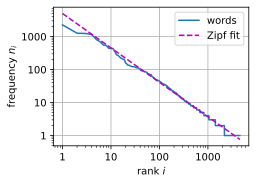

In [11]:
freqs = [freq for token, freq in vocab.token_freqs]
s, c = zipf_fit(freqs)
print(f'Zipf exponent s = {s:.2f}')
ranks = np.arange(1, len(freqs) + 1)
d2l.plot(ranks, [freqs, np.exp(c) * ranks ** -s], xlabel='rank $i$',
         ylabel='frequency $n_i$', xscale='log', yscale='log',
         legend=['words', 'Zipf fit'])

<!-- d2l:prose id=language-model-md-11 fw=all -->

The fitted exponent sits close to 1, matching Zipf's classic observation
across natural languages. Power-law distributions are heavy-tailed: although
any individual rare word appears infrequently, there are so many distinct rare
words that together they account for a substantial share of any text. To see
whether bigrams and trigrams behave similarly, we compute their frequency
curves, fit their Zipf exponents, measure the fraction of distinct $n$-grams
that appear only once, and plot all three curves together.

1-grams: s = 1.04, 52% of distinct 1-grams occur once
2-grams: s = 0.69, 82% of distinct 2-grams occur once
3-grams: s = 0.47, 95% of distinct 3-grams occur once


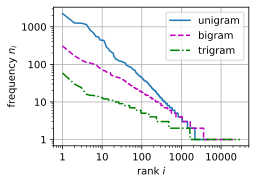

In [12]:
counts = [sorted(collections.Counter(zip(*(words[i:] for i in range(n))))
                 .values(), reverse=True) for n in (1, 2, 3)]
for n, f in zip((1, 2, 3), counts):
    print(f'{n}-grams: s = {zipf_fit(f)[0]:.2f}, '
          f'{np.mean(np.array(f) == 1):.0%} of distinct {n}-grams occur once')
d2l.plot([np.arange(1, len(f) + 1) for f in counts], counts,
         xlabel='rank $i$', ylabel='frequency $n_i$', xscale='log',
         yscale='log', legend=['unigram', 'bigram', 'trigram'])

<!-- d2l:prose id=language-model-md-12 fw=all -->

Word pairs and triples also follow power laws, albeit with smaller exponents
(roughly 0.7 and 0.5). Crucially for count-based models, the tail grows
dramatically heavier as $n$ increases: while half of all distinct words occur
only once, more than nine in ten distinct trigrams are singletons whose
probability estimates rest on a lone observation. It is this heavy tail that
produces the deluge of unseen trigrams on held-out text: any model that
estimates each context independently requires exponentially more data as the
context lengthens.

## Perplexity and Smoothing

### Perplexity

Inspection of the count tables revealed severe sparsity that our sample
generations had concealed. Before attempting to repair these tables, we need a
principled quantitative metric so we can tell whether a modification truly
improves generalization. Evaluating the joint probability of held-out text is
an obvious starting point, but raw sequence probabilities shrink exponentially
with document length: every model assigns a vastly smaller probability to
Tolstoy's *War and Peace* than to Saint-Exupéry's *The Little Prince*,
regardless of model quality. What we need is a per-token average.

Information theory gives us exactly that. In
that section, we saw that the cross-entropy loss of a
probabilistic classifier equals the *surprisal* of the true label—the negative
logarithm of the probability assigned to it. Since a language model is a
next-token classifier at every position, we evaluate it by its average
surprisal across all $T$ tokens of the sequence:

$$\frac{1}{T} \sum_{t=1}^T -\log P(x_t \mid x_{<t}),$$

where $P$ is the model's predictive distribution and $x_t$ is the actual token
at step $t$. Because this average normalizes by length, documents of different
lengths become comparable. In natural language processing, it is customary to
report the exponential of the equation, known as *perplexity*
[@Jelinek.Mercer.Bahl.ea.1977]:

$$\textrm{PPL} = \exp\left(-\frac{1}{T} \sum_{t=1}^T \log P(x_t \mid x_{<t})\right).$$

Equivalently, perplexity is the geometric mean of the inverse probability
assigned to each observed token. A model that assigns probability $1/4$ to
every target token achieves a perplexity of 4, matching the uncertainty of a
uniform choice among four equally likely candidates. Perplexity is therefore
naturally interpreted as the model's *effective branching factor* per token.
Three limiting cases anchor the scale:

* A model that always predicts the true token with probability 1 achieves the
  minimum possible perplexity of 1.
* A model that assigns probability 0 to even a single observed token incurs
  infinite perplexity.
* A baseline model predicting the uniform distribution over the vocabulary
  achieves perplexity $|\mathcal{V}|$, setting an upper bound that any useful
  model must beat.

Our unsmoothed maximum likelihood $n$-grams immediately run into the second
case: because they assign zero probability to every unseen $n$-gram, a single
novel trigram in the held-out text sends perplexity to infinity. To evaluate
and compare count models meaningfully, we must first *smooth* the counts to
eliminate zeros.

### Laplace Smoothing

The classical remedy is *Laplace smoothing* (also called add-$\alpha$
smoothing), which adds a positive constant $\alpha > 0$ to every count and
$\alpha |\mathcal{V}|$ to the denominator so that the resulting distribution
remains normalized:

$$\hat{P}(x_t \mid x_{t-n+1}, \ldots, x_{t-1}) = \frac{N(x_{t-n+1}, \ldots, x_{t}) + \alpha}{N(x_{t-n+1}, \ldots, x_{t-1}) + \alpha |\mathcal{V}|}.$$

Every unseen $n$-gram now receives a small positive probability, and any
completely unseen context defaults to the uniform distribution
$1/|\mathcal{V}|$. The idea predates language modeling by two centuries:
Laplace introduced it with $\alpha = 1$ to estimate the probability that the
sun will rise tomorrow given that it has risen every day so far.

Let us first add a Laplace-smoothed `prob` method to `NGramLM` that implements
the equation using the model's stored smoothing constant
`alpha`.

In [13]:
@d2l.add_to_class(NGramLM)
def prob(self, context, token):
    """Laplace-smoothed P(token | last n-1 tokens of context)."""
    ctx = tuple(context[len(context) - self.n + 1:])
    num = self.cont.get(ctx, {}).get(token, 0) + self.alpha
    return num / (self.total.get(ctx, 0) + self.alpha * self.vocab_size)

<!-- d2l:prose id=language-model-md-13 fw=all -->

With `prob` in place, `eval_nll` sums the negative log-likelihood across a
token sequence so we can compute held-out perplexity on `words_val` for each
$n$-gram order.

In [14]:
def eval_nll(model, tokens):
    """Total negative log-likelihood of tokens, in nats."""
    return -sum(math.log(model.prob(tokens[max(0, t - model.n + 1):t],
                                    tokens[t]))
                for t in range(len(tokens)))

for n, model in models.items():
    ppl = math.exp(eval_nll(model, words_val) / len(words_val))
    print(f'{n}-gram held-out perplexity, Laplace smoothing: {ppl:7.1f}')

1-gram held-out perplexity, Laplace smoothing:   840.6
2-gram held-out perplexity, Laplace smoothing:   753.6
3-gram held-out perplexity, Laplace smoothing:  2481.4


<!-- d2l:prose id=language-model-md-14 fw=all -->

Under Laplace smoothing, the trigram model, whose generated samples
looked most convincing, actually suffers the *worst* held-out perplexity by a
wide margin, while the bigram barely edges past the unigram. Count sparsity
explains both outcomes: when 87% of held-out trigrams are unseen, the vast
majority of trigram predictions collapse into nearly uniform smoothed guesses.
Nor can tuning $\alpha$ save it: even the optimal $\alpha$ from exercise
2 leaves trigram perplexity above
2,400. Fluent samples turned out to be a misleading guide to generalization.

These numbers expose the two core flaws of Laplace smoothing. First, it
distributes probability mass equally across all unseen successors, ignoring
how plausible each word is in general. Second, it fails to fall back on
shorter contexts: an unseen trigram receives the same flat estimate regardless
of whether its final two words form a frequent bigram or an implausible pair.

### Kneser--Ney Smoothing

Kneser--Ney smoothing [@Kneser.Ney.1995], in the interpolated formulation
of @Chen.Goodman.1999, addresses both flaws and reigned as the
strongest count-based language model for two decades. Denote by $u$ a context
of $n-1$ tokens, by $w$ the next token, and by $u'$ the shorter context
obtained by dropping the oldest token of $u$. The method combines three
interlocking ideas.

The first is *absolute discounting*. Empirical counts systematically
overestimate the true frequencies of rare events: an $n$-gram observed once in
training will, on average, appear fewer than once in a fresh sample of the
same size because of selection bias among the huge pool of rare $n$-grams.
Subtracting a fixed discount $0 < D < 1$ from every nonzero count corrects
this upward bias, most strongly for small counts where the distortion is
largest, and frees a total probability mass of $D\,S(u)/N(u)$ in context $u$,
where $S(u)$ is the number of distinct token types observed immediately after
$u$ in training.

The second idea is *interpolation*: rather than spreading the discounted mass
uniformly, we allocate it to the next-lower-order estimate $P_\textrm{KN}(w \mid u')$,
which is defined recursively in the exact same way down to the uniform floor
$1/|\mathcal{V}|$:

$$P_\textrm{KN}(w \mid u) = \frac{\max(N(u, w) - D, 0)}{N(u)} + \frac{D\,S(u)}{N(u)}\, P_\textrm{KN}(w \mid u').$$

Under this recursion, a frequently seen context relies primarily on its own
empirical counts, whereas a context observed with many diverse successors
shifts more weight to the shorter context—reflecting the intuition that a
context with many past continuations is also more likely to admit novel ones.
If a context $u$ was never observed in training at all, all probability mass
passes directly down: $P_\textrm{KN}(w \mid u) = P_\textrm{KN}(w \mid u')$.

The third idea changes *what* the lower orders count. Because the lower-order
distribution is invoked primarily to score words that have not appeared in the
longer context, it should measure how readily a word enters *new* contexts
rather than its raw corpus frequency. In our training text, `"traveller"`
appears 49 times, yet follows only two distinct words (`"time"` 48 times and
`"real"` once), whereas `"said"` appears 76 times after 48 different
predecessors. Raw unigram frequency would mistakenly predict `"traveller"`
almost as eagerly as `"said"` in an unfamiliar context, whereas counting
distinct predecessors recognizes that `"traveller"` rarely appears without
`"time"`. (The classic NLP example is `"Francisco"`, which is common in news
text yet almost exclusively preceded by `"San"`.) Kneser--Ney therefore
replaces $N(u, w)$ at every order below the highest with the *continuation
count*, the number of distinct tokens that precede $(u, w)$ in training, with
$N(u)$ and $S(u)$ computed analogously from those continuation counts.

Better still, the discount parameter $D$ has a clean closed-form estimate
derived by @Ney.Essen.Kneser.1994: $D = c_1 / (c_1 + 2 c_2)$ at each
order, where $c_1$ and $c_2$ are the numbers of distinct $n$-grams at that
order occurring exactly once and twice, respectively (using continuation
counts below the highest order).

The function `kneser_ney` below implements the equation in full: it
tallies the highest-order $n$-grams, derives continuation counts for every
lower order from the distinct tuples one order above, computes $N(u)$, $S(u)$,
and $D$, and evaluates the recursion across a token sequence, returning the
log-probability (in nats) of each token given its available prefix.

In [15]:
def kneser_ney(train, tokens, vocab_size, n=3):
    """Interpolated Kneser-Ney log-probabilities (nats) of each of tokens."""
    counts = {n: collections.Counter(zip(*(train[i:] for i in range(n))))}
    for k in range(n - 1, 0, -1):  # Lower orders: continuation counts
        counts[k] = collections.Counter(g[1:] for g in counts[k + 1])
    stats = {}
    for k, c in counts.items():
        c1, c2 = (sum(x == r for x in c.values()) for r in (1, 2))
        N, S = collections.Counter(), collections.Counter()
        for g, x in c.items():
            N[g[:-1]] += x
            S[g[:-1]] += 1
        stats[k] = c, N, S, c1 / max(c1 + 2 * c2, 1)
    logp = []
    for i in range(len(tokens)):
        p = 1 / vocab_size  # Below the unigram: uniform
        for k in range(1, min(n, i + 1) + 1):
            c, N, S, D = stats[k]
            g = tuple(tokens[i - k + 1:i + 1])
            if N[g[:-1]]:  # An unseen context passes p down unchanged
                p = (max(c[g] - D, 0) + D * S[g[:-1]] * p) / N[g[:-1]]
        logp.append(math.log(p))
    return logp

<!-- d2l:prose id=language-model-md-15 fw=all -->

Before scoring the full validation split, let us watch Kneser--Ney at work on
our familiar context `"the time"`. Below, we print the trigram discount $D$
and compare the probabilities that Kneser--Ney and Laplace smoothing assign to
three candidate continuations: `"traveller"`, which followed `"the time"` in
47 of its 87 training occurrences, and two words that never followed it in
training, `"was"` and `"filby"`.

In [16]:
c3 = collections.Counter(zip(words_train, words_train[1:], words_train[2:]))
c1, c2 = (sum(x == r for x in c3.values()) for r in (1, 2))
print(f'trigram discount D = {c1 / (c1 + 2 * c2):.2f}')
for w in ('traveller', 'was', 'filby'):
    lp = kneser_ney(words_train, ['the', 'time', w], vocab_size)[-1]
    print(f'P({w} | the time): Kneser-Ney {math.exp(lp):.2g}, '
          f'Laplace {models[3].prob(["the", "time"], w):.2g}')

trigram discount D = 0.93
P(traveller | the time): Kneser-Ney 0.53, Laplace 0.36
P(was | the time): Kneser-Ney 0.00037, Laplace 7.7e-05
P(filby | the time): Kneser-Ney 2.3e-05, Laplace 7.7e-05


<!-- d2l:prose id=language-model-md-16 fw=all -->

The trigram discount is roughly $0.9$, subtracting nearly an entire count from
every observed trigram—a vivid reflection of how noisy single-count
observations are. For a common trigram with count 47, subtracting $0.9$ barely
moves the needle, keeping `"traveller"` close to its empirical frequency of
$47/87$, whereas Laplace smoothing squanders nearly a third of that
probability mass across the vocabulary. The contrast on unseen continuations
is even sharper: Laplace smoothing treats `"was"` and `"filby"` identically,
whereas Kneser--Ney recognizes that `"was"` follows a wide variety of contexts
while `"filby"` appears in very few, separating their probabilities by more
than an order of magnitude. Let us measure how much this gains on the held-out
text.

In [17]:
for n in (1, 2, 3):
    kn = kneser_ney(words_train, words_val, vocab_size, n)
    print(f'{n}-gram held-out perplexity, Kneser-Ney: '
          f'{math.exp(-sum(kn) / len(kn)):7.1f}')

1-gram held-out perplexity, Kneser-Ney:   592.8
2-gram held-out perplexity, Kneser-Ney:   312.3


3-gram held-out perplexity, Kneser-Ney:   300.1


<!-- d2l:prose id=language-model-md-17 fw=all -->

Kneser--Ney completely reverses the ranking. Even its unigram beats Laplace's,
its bigram cuts perplexity roughly in half, and its trigram outperforms all
other count models because unseen trigrams back off smoothly to well-calibrated
bigram and unigram continuation estimates rather than collapsing to a uniform
guess. Notice, though, that the trigram improves only modestly over the
bigram: because most held-out trigrams remain unseen, the trigram model falls
back to the bigram for the majority of positions. Achieving low perplexity on
*unseen* text is the defining test of a language model, and perplexity will
serve as our primary benchmark for the neural models that follow.

Still, Kneser--Ney shares a fundamental limitation with every count-based
method: while smoothing redistributes probability mass away from zeros, it
cannot infer which unseen combinations are semantically plausible. Because a
count table treats each token as an atomic, unrelated symbol, it has no way of
knowing that `"cat"` and `"feline"` share syntactic and semantic roles, or
that `"I want to eat, grandma"` is benign whereas `"I want to eat grandma"` is
alarming. Sharing statistical strength across related words and contexts
demands learned continuous representations—the exact motivation for turning to
neural networks in that section.

### Bits per Byte

Perplexity suffers from one crucial limitation: it is tied to the choice of
tokenization. Because a character model chooses among 27 symbols at each step
while a word model chooses among thousands, their raw perplexities are on
completely different scales and cannot be compared directly. Yet tokenization
is an internal design choice (that section), and a fair
evaluation metric must be invariant to it. Fortunately, the remedy is simple:
replace the denominator. Instead of dividing total surprisal by the number of
tokens, we divide by the number of *bytes* in the evaluated text, a quantity
determined solely by the text itself. Measuring surprisal in bits (base-2
logarithms) gives *bits per byte* (bpb):

$$\textrm{bpb} = \frac{1}{B} \sum_{t=1}^T -\log_2 P(x_t \mid x_{<t}),$$

where $B$ is the length of the evaluated text in UTF-8 bytes. Bits per byte
has an immediate operational meaning as a lossless compression rate: paired
with an arithmetic coder, a model achieving $\textrm{bpb}$ bits per byte
compresses the text to $\textrm{bpb}/8$ of its original byte size.

To compare perplexity and bits per byte directly, we fit trigram models, first
with Laplace smoothing and then with Kneser--Ney, on the same normalized
training text under three tokenizations: characters, words, and a 1,024-token
BPE vocabulary (trained on the normalized training split using the tokenizer
from that section). One subtlety is required to keep the
comparison honest: whenever the word model predicts `<unk>`, it has not yet
specified *which* out-of-vocabulary word occurred. To encode the held-out text
losslessly, the word model must still spell each unknown word out, so we add
$\log_2 27$ bits per letter plus the trailing space—the cost of coding each
character uniformly from the 27 normalized symbols.

In [18]:
bpe = d2l.BPETokenizer(vocab_size=1024, pattern=d2l.BPETokenizer.GPT2_PATTERN)
bpe.train(text[:split])
streams = {'character': (list(text[:split]), list(text[split:]),
                         len(set(text))),
           'BPE (1,024)': (bpe.encode(text[:split]), bpe.encode(text[split:]),
                           bpe.vocab_size),
           'word': (words_train, words_val, vocab_size)}
n_bytes = len(text[split:].encode('utf-8'))
spell = sum((len(w) + 1) * math.log(27)  # Nats to spell out the <unk> words
            for w in text[split:].split() if w not in known)
print(f'{"tokenization":>12} {"|V|":>5} {"tokens":>7} {"ppl":>7} '
      f'{"bpb":>5} {"KN bpb":>6}')
for name, (train, val, m) in streams.items():
    nll = eval_nll(NGramLM(train, 3, m), val)
    nll_kn = -sum(kneser_ney(train, val, m))
    extra = spell if name == 'word' else 0
    print(f'{name:>12} {m:>5} {len(val):>7} {math.exp(nll / len(val)):>7.1f} '
          f'{(nll + extra) / math.log(2) / n_bytes:>5.2f} '
          f'{(nll_kn + extra) / math.log(2) / n_bytes:>6.2f}')

tokenization   |V|  tokens     ppl   bpb KN bpb
   character    27   17345     6.4  2.68   2.67


 BPE (1,024)  1024    5509   281.6  2.58   1.90
        word  4316    3373  2481.4  2.81   2.22


<!-- d2l:prose id=language-model-md-18 fw=all -->

Measured by raw perplexity, the three Laplace-smoothed models appear separated
by more than two orders of magnitude; measured by bits per byte, they lie
within a third of a bit of one another, and the character model, seemingly far
ahead in perplexity, no longer wins. For a fixed Markov order $n$, coarser
tokens span longer stretches of text: two words of context reach back roughly
ten characters, whereas two characters scarcely cover a syllable. The word
model would lead were it not penalized by out-of-vocabulary words, whose
spelling cost adds roughly $0.6$ bits per byte and drops it to last place
under Laplace smoothing. Byte-level BPE suffers no OOV penalty at all,
achieving the strongest compression and providing yet another reason modern
language models adopt subword tokenization.

In the final column, Kneser--Ney trims more than half a bit per byte from both
the BPE and word trigrams while leaving the character trigram virtually
unchanged, since with only 27 symbols very few character trigrams are unseen
and smoothing has little work to do. At roughly $1.9$ bits per byte, the
Kneser--Ney BPE trigram is our strongest count-based baseline.

Bits per byte is therefore the standard metric when comparing modern language
models built on different vocabularies (for instance, a 50,000-token model
against a 200,000-token model). Three benchmarks help calibrate the scale:
Shannon's classic human-prediction experiments estimated the entropy of
printed English at roughly 1 bit per character [@Shannon.1951]; modern
neural language models compress diverse web text to well below 1 bit per byte;
and the count-based models of this section sit between roughly $1.9$ and $2.8$
bits per byte.

## Partitioning Sequences

The neural language models in the upcoming sections ingest minibatches of
fixed-length BPE token subsequences produced by the tokenizer from
that section. Let us assemble that data pipeline now.

Picture the tokenized corpus as a single contiguous stream of token ids
$x_1, x_2, x_3, \ldots$. An input window of length $T$ starting at index $t$
contains $x_t, \ldots, x_{t+T-1}$, and its paired target is the same window
shifted one token to the right, $x_{t+1}, \ldots, x_{t+T}$. As the model steps
through the input window, it predicts the next token at every position, so
each window supplies $T$ supervised next-token targets. Every starting offset
in the corpus except the final $T$ tokens defines a valid window, with
adjacent windows overlapping in all but one token
(the figure). During training, we sample minibatches of
these windows at random to provide the shuffling that stochastic gradient
descent requires.

![The first two input windows of length $T = 5$ over the opening BPE tokens of *The Time Machine* (␣ marks a leading space). Each target is its input shifted forward by one token, and consecutive windows overlap in all but one token; a minibatch gathers windows drawn at random.](../img/mdl-rnn-partitioning.svg)

The `TimeMachine` constructor below puts the pipeline together: it downloads
the novella, trains the BPE tokenizer from that section,
encodes the text into integer ids, and stacks all overlapping windows of
length `num_steps` into aligned input (`X`) and target (`Y`) arrays. The
trained tokenizer is stored on both `data.tokenizer` and `data.vocab` so that
we can decode ids back to text and query `len(data.vocab)` uniformly across
tokenization modes.

In [19]:
@d2l.add_to_class(d2l.TimeMachine)
def __init__(self, batch_size, num_steps, num_train=50000, num_val=5000,
             tokenization='bpe', vocab_size=1024):
    super(d2l.TimeMachine, self).__init__()
    self.save_hyperparameters()
    raw_text = self._download()
    if tokenization == 'bpe':
        self.tokenizer = d2l.BPETokenizer(
            vocab_size, pattern=d2l.BPETokenizer.GPT2_PATTERN)
        self.tokenizer.train(raw_text)
        corpus, self.vocab = self.tokenizer.encode(raw_text), self.tokenizer
    else:  # tokenization='char': characters, via TimeMachine.build
        corpus, self.vocab = self.build(raw_text)
    windows = [corpus[i:i+num_steps+1] for i in range(len(corpus)-num_steps)]
    # Drop the windows that straddle the split, so that no validation token
    # is a training target
    windows = windows[:num_train] + windows[num_train+num_steps:]
    array = d2l.tensor(windows)
    self.X, self.Y = array[:,:-1], array[:,1:]

<!-- d2l:prose id=language-model-md-19 fw=all -->

We reserve the first `num_train` windows for training and `num_val` subsequent
windows for validation. Because adjacent windows overlap heavily, the windows
immediately following the training split would contain tokens that already
appeared as training targets; dropping a buffer of `num_steps` boundary
windows prevents any data leakage between training and validation. During
validation, minibatches are iterated sequentially without shuffling.

In [20]:
@d2l.add_to_class(d2l.TimeMachine)
def get_dataloader(self, train):
    idx = slice(0, self.num_train) if train else slice(
        self.num_train, self.num_train + self.num_val)
    return self.get_tensorloader([self.X, self.Y], train, idx)

<!-- d2l:prose id=language-model-md-20 fw=all -->

Each minibatch consists of two integer tensors of shape
(`batch_size`, `num_steps`). Decoding a sample row confirms that `X` contains
Wells' prose and that `Y` is shifted forward by exactly one token.

In [21]:
data = d2l.TimeMachine(batch_size=2, num_steps=10)
for X, Y in data.train_dataloader():
    print('X:', X, '\nY:', Y)
    break
print('X[0]:', repr(data.tokenizer.decode([int(i) for i in X[0]])))
print('Y[0]:', repr(data.tokenizer.decode([int(i) for i in Y[0]])))

X: tensor([[ 302,  115,  280,  408,  277,  272,  360,  270,  432,  260],
        [ 353,  258, 1012,  480,  342,   46,  533,  260,   10,   84]]) 
Y: tensor([[ 115,  280,  408,  277,  272,  360,  270,  432,  260,  335],
        [ 258, 1012,  480,  342,   46,  533,  260,   10,   84,  355]])
X[0]: 'sts cast and filed into the'
Y[0]: 's cast and filed into the re'


<!-- d2l:prose id=language-model-md-21 fw=all -->

A window of BPE tokens supplies far more context than any count table can
exploit—our word tables already ran out of data at just two words of history.
In the next section, we replace lookup tables with a neural network that
compresses an arbitrarily long prefix into a learned hidden state.

## Summary

A language model assigns probabilities to token sequences, and the chain rule
of probability reduces this task to next-token prediction, enabling the same
model to both score and generate text. Under a Markov assumption, $n$-gram
models estimate next-token probabilities directly from corpus counts; although
simple to construct and capable of locally fluent samples, they suffer from
exponentially growing context spaces and Zipfian heavy tails, leaving most
observed $n$-grams as singletons and causing the models to memorize rather
than generalize. Perplexity, the exponential of average per-token
cross-entropy, measures a model's effective branching factor and exposes why
Laplace-smoothed trigrams perform poorly on held-out text. Interpolated
Kneser--Ney smoothing discounts observed counts and redistributes the freed
mass to lower-order continuation counts, yielding the strongest count-based
models, yet it still cannot generalize across semantically related tokens.
Because perplexity depends on vocabulary granularity, bits per byte provides
a tokenization-invariant compression rate for fair cross-model comparisons.
Finally, to feed neural language models in the sections ahead, we convert the
BPE-tokenized corpus into overlapping fixed-length input–target windows with a
clean gap preventing leakage into the validation split.

## Exercises

1. **Dense versus sparse storage.** Consider a 5-gram model over a
   vocabulary of $|\mathcal{V}| = 50{,}000$ word tokens.
    1. How many entries does a dense table of the conditional
       probabilities the equation contain?
    1. Suppose instead that only the 5-grams observed in a trillion-token
       corpus are stored, at 16 bytes per entry. How much memory is needed
       at most, and what fraction of all possible 5-grams is covered?
    1. The word vocabulary of that section
       has $|\mathcal{V}| = 4{,}316$ entries, and the code there prints the
       number of distinct word trigrams in the training text. Which
       fraction of all possible trigrams occurs in training? Which fraction
       of the held-out trigrams does? Is the coverage computed in (b)
       therefore a good estimate of how often a query on new text finds
       its 5-gram in the table?

1. [code] **Smoothing constant.** Sweep $\alpha$ in
   the equation over the 19 values
   $\alpha = 10^{k/4}$ for $k = -16, -15, \ldots, 2$, for the unigram,
   bigram, and trigram word models, and plot held-out perplexity against
   $\alpha$ on a logarithmic axis.
    1. How does the best $\alpha$ change with $n$, and why?
    1. Rank the three models, each at its own best $\alpha$, by held-out
       perplexity. How does this ranking differ from the one printed in
       that section with the default $\alpha = 0.01$ of
       `NGramLM`?

1. **Perplexity under skew.** A training corpus over ten symbols consists
   of one symbol 91% of the time and each of the other nine 1% of the
   time.
    1. Compute the perplexity of the unigram model estimated from this
       corpus on a long test text drawn from the same distribution. How
       does it compare with the vocabulary size of ten?
    1. The word-level unigram model of that section chooses
       among thousands of word types. Read off its held-out perplexity as
       an effective number of equally likely choices, and explain with
       Zipf's law the equation why this number is far below
       $|\mathcal{V}|$.

    *Adapted from Daniel Jurafsky and James H. Martin,
    [Speech and Language Processing](https://web.stanford.edu/~jurafsky/slp3/),
    3rd ed. draft, Exercise 3.12.*

1. **Overlapping windows.** `d2l.TimeMachine` builds one row of
   `num_steps + 1` consecutive tokens for every possible start position
   in the corpus. The first `num_steps` tokens of a row form a row of `X`,
   and the last `num_steps` tokens form the matching row of `Y`. The first
   `num_train` rows go to training, the next `num_steps` rows are dropped,
   and the `num_val` rows after them go to validation
   (that section). Take `num_steps=32`,
   `num_train=10000`, and `num_val=5000`.
    1. Counting input and target tokens together, which corpus positions do
       the training rows touch, and which do the validation rows touch?
       How many positions would both touch if no rows were dropped, and
       why would that inflate the validation score?
    1. How many times per epoch does a token in the interior of the
       training range serve as a target?
    1. How many windows does a partition of the entire corpus of about
       66,000 tokens into non-overlapping 32-token windows yield? Compare
       this partition with the 10,000 overlapping training rows in the
       number of windows and in the number of distinct corpus positions
       covered.

1. [code] **Normalization across lengths.** ● `NGramLM` has no
   end-of-sequence token. Train a bigram `NGramLM` with $\alpha = 1$ and
   `vocab_size=3` on a short string over a three-symbol vocabulary. Use
   `prob` and the chain rule the equation to sum the
   probabilities of all sequences of length 2, and separately those of all
   sequences of length 3.
    1. What does each sum equal, and what do the two sums say about the
       model as a distribution over sequences whose length is not fixed in
       advance?
    1. Add an end-of-sequence token to the vocabulary, so that
       `vocab_size=4`, and append it to the training string. Treat a
       sequence as complete once it emits this token. Show that the
       probabilities of all complete sequences now sum to exactly one.
       Which property of the model rules out probability mass on
       sequences that never end?

    *Adapted from Daniel Jurafsky and James H. Martin,
    [Speech and Language Processing](https://web.stanford.edu/~jurafsky/slp3/),
    3rd ed. draft, Exercise 3.5.*

1. [code] **Seen and unseen trigrams.** ● Split the held-out positions
   from the third word on by whether the word trigram ending at that
   position occurred in training. Take the bigram and the trigram word
   models, each at its best $\alpha$ from the sweep of
   problem 2,
   and compute the average negative log-likelihood of each model
   on each group. On which group is the trigram the better model, and how
   does Kneser--Ney the equation exploit this?

<!-- d2l:prose id=language-model-md-22 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/118)